# 01 · Exploratory Data Analysis (EDA)

**Goal.** Build the dataset used in the whole project (500 positive + 500 negative GoEmotions comments), verify its quality, justify each preprocessing decision and describe it before modeling.

**Contents**

1. Loading and filtering (data quality)
2. Balanced dataset and text cleaning
3. Class balance
4. Impact of the preprocessing
5. Text length
6. Vocabulary: frequent and distinctive words
7. Findings and limitations
8. Train/test split and saving the processed data

In [1]:
import sys; sys.path.append("..")      # agrega la raíz del repo a la ruta de módulos para poder hacer "from src..."
from pathlib import Path               # rutas que funcionan igual en Windows, Mac y Linux

import pandas as pd                    # tablas (DataFrames)

# Se importa cada función por nombre (en vez de "import *") para saber de qué módulo viene cada una
from src.preprocessing import (load_raw, aggregate_filtered, assign_sentiment, build_balanced, clean_text, tokenize, split_data, filter_funnel, data_quality, preprocessing_summary, length_percentiles, SEED)
from src.visualize import (plot_filter_funnel, plot_group_distribution, plot_class_balance, plot_length_distribution, plot_top_words, plot_top_bigrams, plot_distinctive_words, plot_wordclouds)

pd.set_option("display.max_colwidth", 90)       # muestra más texto de cada comentario al imprimir tablas

PROCESSED = Path("../data/processed")           # aquí se guardan los CSV listos para los modelos
METRICS = Path("../outputs/metrics")            # aquí se guardan las tablas que van al reporte
PROCESSED.mkdir(parents=True, exist_ok=True)    # crea las carpetas si no existen
METRICS.mkdir(parents=True, exist_ok=True)
print("Random seed:", SEED)

Random seed: 42


## 1. Loading and filtering

The raw CSV files have **one row per rater and comment**. We group by comment and keep an emotion only if **at least 2 raters** marked it (this reproduces the authors' filtered version). Then each comment is assigned a sentiment group with the official mapping: `positive`, `negative`, `ambiguous`, `neutral` or `mixed` (emotions from more than one group).

In [2]:
raw = load_raw()                                # une los 3 CSV: una fila por evaluador y comentario
agreed = aggregate_filtered(raw)                # una emoción cuenta solo si >= 2 evaluadores la marcaron
filtered = assign_sentiment(agreed)             # asigna positive / negative / ambiguous / neutral / mixed

print("Raw rows (one per rater):", f"{len(raw):,}")
print("Unique comments:", f"{raw['id'].nunique():,}")
print("After the agreement filter:", f"{len(filtered):,}")
filtered["group"].value_counts()                # comentarios por grupo (la última línea se muestra como salida)

Raw rows (one per rater): 211,225
Unique comments: 58,011
After the agreement filter: 54,263


group
positive     19020
neutral      16021
negative     10217
ambiguous     4805
mixed         4200
Name: count, dtype: int64

### 1.1 Data quality: what is lost at each step

The table counts how many comments survive each filtering step until we reach the final 1,000.

In [3]:
funnel = filter_funnel(raw, filtered)           # tabla con los comentarios que quedan tras cada paso
funnel.to_csv(METRICS / "eda_filter_funnel.csv", index=False)   # se guarda para usarla en el reporte
funnel

,step,comments,removed
0,Raw rows (one per rater),211225,<NA>
1,Unique comments,58011,<NA>
2,With >= 1 emotion agreed by >= 2 raters,54263,3748
3,Single group: positive or negative only,29237,25026
4,After removing conflicting duplicate texts,29234,3
5,After removing duplicate texts,29021,213
6,Balanced sample (500 + 500),1000,28021


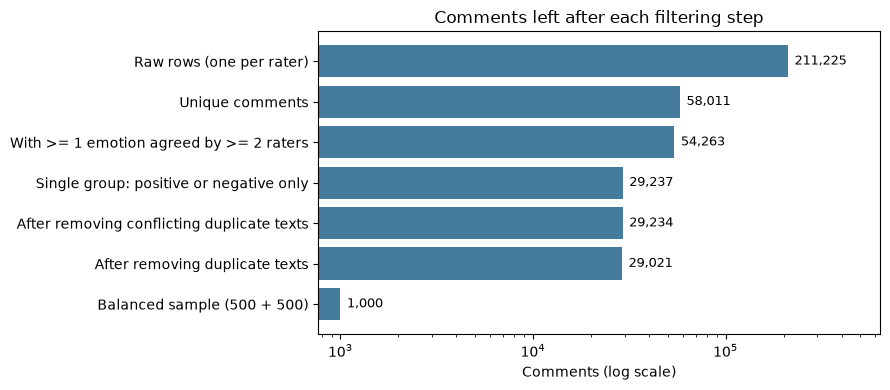

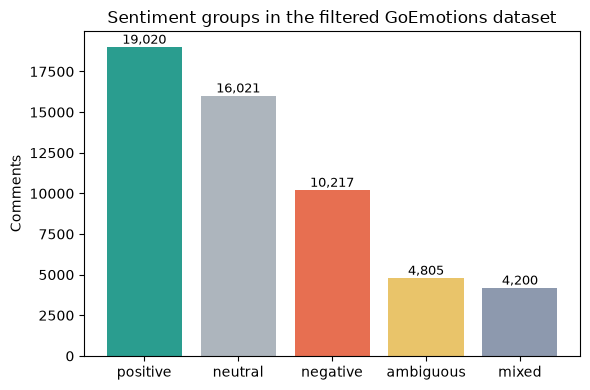

In [4]:
plot_filter_funnel(funnel);                     # embudo del filtrado (escala logarítmica)
plot_group_distribution(filtered);              # los 5 grupos del dataset filtrado completo

**Observations**

- The agreement filter removes 3,748 comments in which no emotion received 2 votes. After it, 54,263 comments remain, the same number reported for the authors' filtered version, so the pipeline is correct.
- The biggest reduction (25,026 comments) comes from keeping a single group: it removes the 16,021 neutral, 4,805 ambiguous and 4,200 mixed comments, as required.
- Only 3 comments appear with contradictory labels and 213 are duplicated texts, so the label noise from repeated texts is small.
- The full positive/negative pool is **imbalanced** (19,020 positive vs 10,217 negative, about 65 % / 35 %). This is why we sample 500 per class instead of using everything: both classes have the same weight and accuracy is not inflated by the majority class.

## 2. Balanced dataset and text cleaning

`build_balanced` keeps only positive and negative comments, removes conflicting and duplicated texts, and samples 500 per class with a fixed seed (`SEED = 42`). Then we create:

- `clean`: lowercase text, without URLs, punctuation or emojis, and without stopwords (negations are kept).
- `n_words`: words in the original text.
- `n_tokens`: tokens after the cleaning.

In [5]:
balanced = build_balanced(filtered)                                   # 500 positivos + 500 negativos, mezclados
balanced["clean"] = balanced["text"].apply(clean_text)                # texto limpio (sin URLs, puntuación, emojis ni stopwords)
balanced["n_words"] = balanced["text"].str.split().str.len()          # palabras del texto original
balanced["n_tokens"] = balanced["clean"].str.split().str.len()        # tokens tras la limpieza
print("Shape:", balanced.shape)
data_quality(balanced).to_frame()                                     # nulos, duplicados y textos vacíos

Shape: (1000, 7)


,value
rows,1000
null_cells,0
duplicated_texts,0
empty_texts,0
empty_after_cleaning,0


In [6]:
# 3 comentarios por clase: texto original vs. texto limpio (los datos ya están mezclados con la semilla)
balanced.groupby("group").head(3)[["group", "text", "clean"]]

,group,text,clean
0,negative,Very sorry for your loss.,sorry loss
1,negative,The more you wind me up the worse it gets for her later on,wind worse gets later
2,negative,"AYY! Anti-Semitism! Didn't expect that from AnCaps, but I'm not surprised.",ayy anti semitism didn't expect ancaps not surprised
4,positive,i hope this grossed u out ur welcome 😎,hope grossed u ur welcome
9,positive,Love the [NAME]. They have a great dynamic and it looks like a genuine friendship.,love [name] great dynamic looks like genuine friendship
11,positive,Knife Fight used to be an awesome cooking comp show,knife fight used awesome cooking comp show


The balanced dataset has no null values, no duplicated texts and no comment that becomes empty after cleaning, so every comment can be used by the models.

## 3. Class balance

{'negative': 500, 'positive': 500}


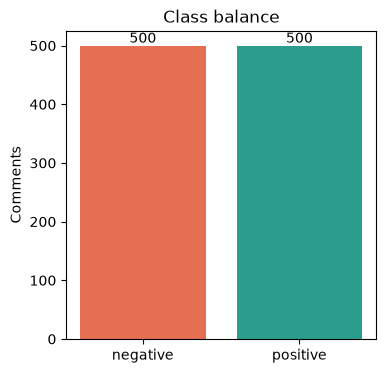

In [7]:
print(balanced["group"].value_counts().to_dict())
plot_class_balance(balanced);                   # 500 vs 500 por construcción

## 4. Impact of the preprocessing

Decisions made in `src/preprocessing.py`:

| Step | Decision | Reason |
|---|---|---|
| Lowercase | yes | `Good` and `good` are the same word; reduces vocabulary size |
| URLs | removed | they carry no sentiment |
| Punctuation and emojis | removed | simple tokenization with a regular expression; **emojis are lost** (see limitations) |
| `[NAME]`, `[RELIGION]` | kept as tokens | they are dataset markers, not noise |
| Apostrophes | `didn't`, `it's` stay in one token | splitting would create meaningless tokens like `didn` and `t` |
| Stopwords | removed (NLTK list) | they reduce length without adding sentiment |
| **Negations** | **kept** (`not`, `no`, `never`, `n't` words) | `not good` and `good` have opposite sentiment |

In [8]:
example = "I didn't like it, it's NOT good!! 😡 Check https://example.com [NAME]'s dog"
print("Original:         ", example)
print("With stopwords:   ", tokenize(example, remove_stopwords=False))   # solo limpieza
print("Without stopwords:", tokenize(example, remove_stopwords=True))    # limpieza + sin stopwords (se conservan negaciones)

Original:          I didn't like it, it's NOT good!! 😡 Check https://example.com [NAME]'s dog
With stopwords:    ['i', "didn't", 'like', 'it', "it's", 'not', 'good', 'check', '[name]', 's', 'dog']
Without stopwords: ["didn't", 'like', 'not', 'good', 'check', '[name]', 'dog']


In [9]:
# Efecto de cada paso sobre la longitud promedio, el total de tokens y el tamaño del vocabulario
summary = preprocessing_summary(balanced["text"])
summary.to_csv(METRICS / "eda_preprocessing_summary.csv")
summary

,avg_length,total_tokens,vocab_size
variant,,,
Original (split on whitespace),13.18,13183,4205
"Tokenized, with stopwords",13.21,13206,3010
"Tokenized, without stopwords",7.16,7161,2873


Removing stopwords roughly halves the average length of a comment, and punctuation and case normalization reduce the number of distinct words. A smaller vocabulary means fewer parameters in the embedding layer, which matters with only 800 training comments.

## 5. Text length

Recurrent models need a fixed `max_len`: shorter comments are padded and longer ones are truncated. We use the 95th percentile of the length (tokens, stopwords kept) as a reference value.

In [10]:
print(balanced.groupby("group")[["n_words", "n_tokens"]].describe().round(2).T)   # estadísticas por clase

pct = length_percentiles(balanced["text"])      # percentiles de longitud (tokens, sin quitar stopwords)
pct

group           negative  positive
n_words  count    500.00    500.00
         mean      13.69     12.68
         std        6.58      6.48
         min        2.00      1.00
         25%        8.00      7.00
         50%       14.00     12.00
         75%       19.00     18.00
         max       29.00     29.00
n_tokens count    500.00    500.00
         mean       7.50      6.82
         std        3.70      3.61
         min        1.00      1.00
         25%        4.00      4.00
         50%        7.00      6.50
         75%       10.00      9.00
         max       21.00     18.00


p50     13
p90     22
p95     24
p99     27
p100    30
dtype: int64

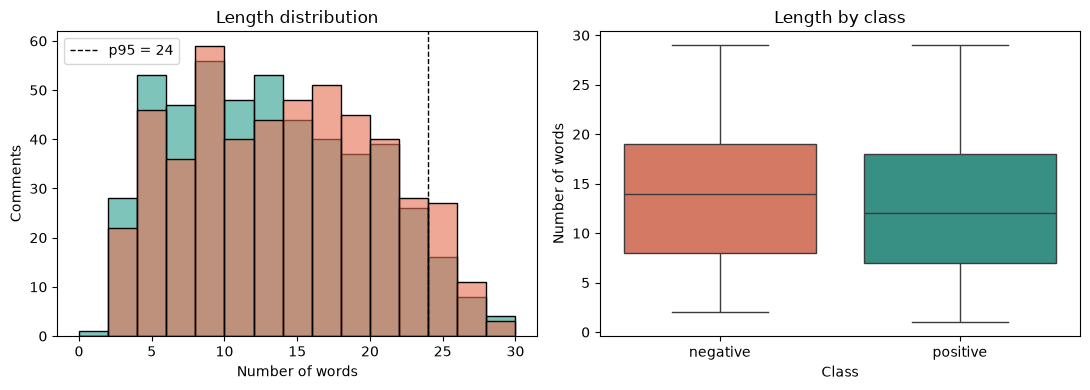

In [11]:
max_len_ref = int(pct["p95"])                   # longitud que no supera el 95 % de los comentarios
plot_length_distribution(balanced, vline=max_len_ref);   # histograma + boxplot, con una línea en el p95

**Observations**

- Both classes have a very similar length distribution (around 13 words on average, 14 for negative and 13 for positive, and a maximum of 29), so **length is a weak feature** to separate them (the difference is about one word, smaller than the standard deviation).
- The comments are short (the dataset limits them to 30 tokens), so a `max_len` near the 95th percentile covers almost every comment with little padding.

## 6. Vocabulary

First the most frequent words and bigrams per class. Then the words that best **separate** the classes (log-odds ratio), which a raw frequency count cannot show.

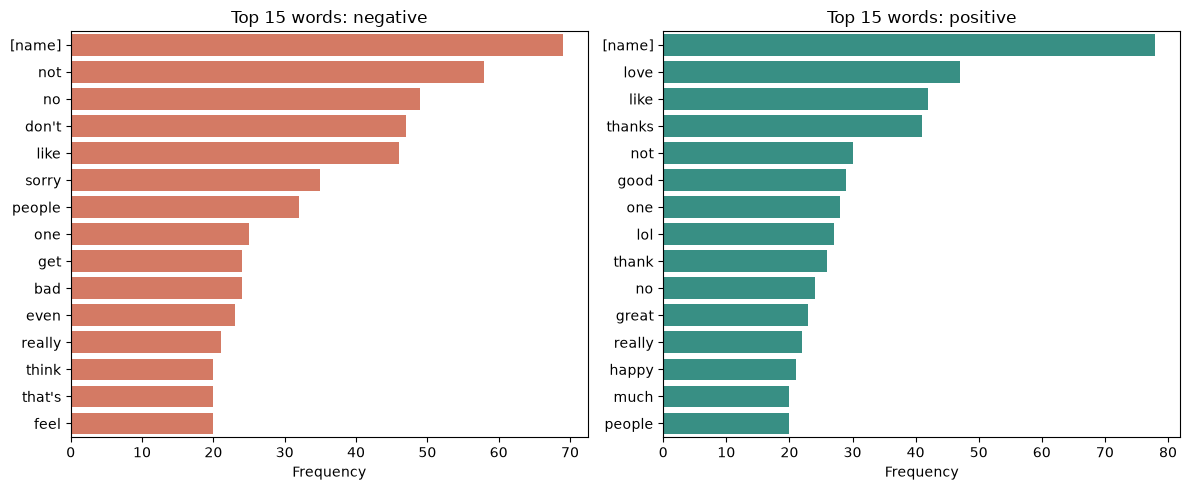

In [12]:
plot_top_words(balanced);                       # 15 palabras más frecuentes por clase

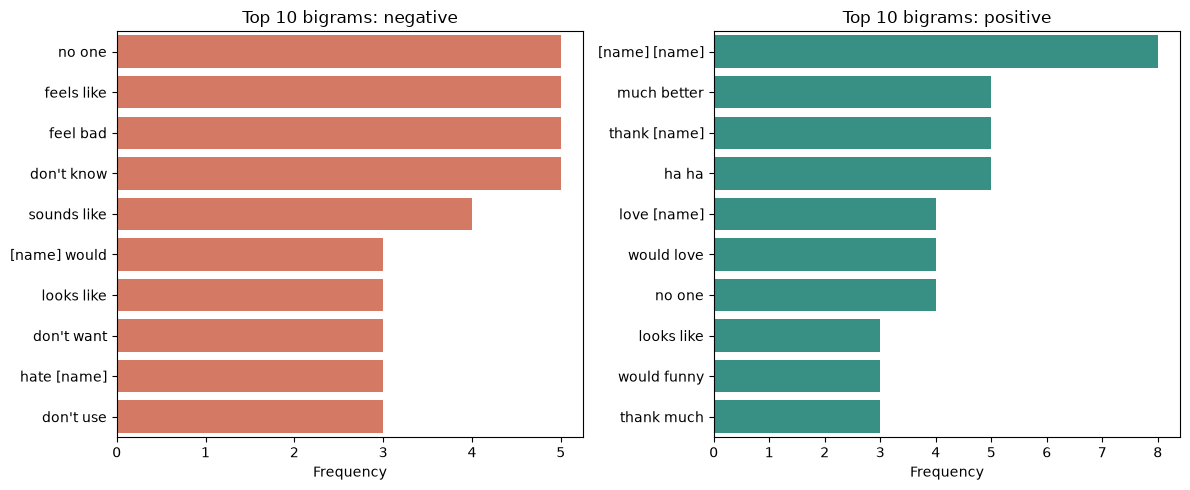

In [13]:
plot_top_bigrams(balanced);                     # 10 bigramas (pares de palabras seguidas) más frecuentes por clase

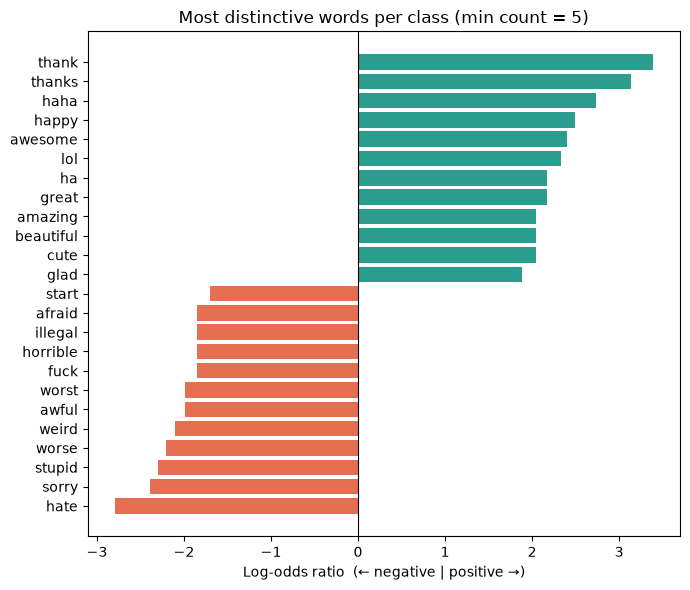

In [14]:
plot_distinctive_words(balanced);               # palabras más asociadas a cada clase (log-odds)

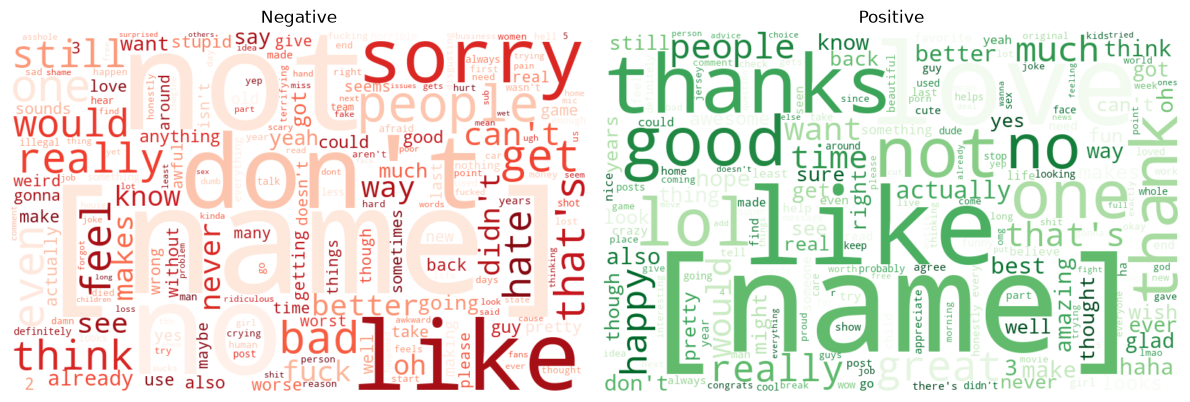

In [15]:
try:
    plot_wordclouds(balanced);                  # nube de palabras por clase (necesita: pip install wordcloud)
except ImportError as e:
    print(e)                                    # si falta la librería, el resto del notebook sigue funcionando

**Observations**

- The most frequent words are similar in both classes (the `[NAME]` marker and common words such as negations or `like`), so raw frequency does **not** separate them well.
- The log-odds plot does: positive comments are marked by words such as *thank(s)*, *happy*, *awesome*, *lol*, *haha*; negative ones by *hate*, *sorry*, *stupid*, *worst*, *horrible*.
- The frequent bigrams are short conversational phrases typical of Reddit, which confirms that the comments are informal and short.
- Negations (`not`, `no`, `don't`) are frequent in both classes. This supports keeping them: they change the meaning of the next word and are exactly the kind of context a sequence model can use but a bag of words cannot.

## 7. Findings and limitations

**Findings**

- The pipeline reproduces the numbers reported by the authors (54,263 filtered comments; 19,020 positive and 10,217 negative), so the data preparation is correct.
- The data has no nulls, no duplicated texts and no empty comments after cleaning.
- Length barely distinguishes the classes; vocabulary does, mainly through a few strongly emotional words. A model that learns these words can reach good accuracy, so the harder cases will be comments without them (irony, implicit emotion).

**Limitations**

- Only 1,000 comments (800 for training) are used out of about 29,000 available, so results will have noticeable variance between runs.
- Emojis are removed by the tokenizer, but in Reddit they often carry sentiment.
- Irony and sarcasm are not captured by word-level preprocessing.
- The tokenizer can leave small artifacts: a possessive such as `[NAME]'s` becomes `[name]` and `s`.

## 8. Train/test split and saving the processed data

Stratified split (80 % / 20 %) with the same seed, so every team member gets the same sets. We verify that both sets keep the 50/50 proportion and share no comment.

In [16]:
train, test = split_data(balanced)              # 800 para entrenar y 200 para probar, estratificado por clase
print("Sizes:", len(train), len(test))
print("Train labels:", train["label"].value_counts().to_dict(), "| Test labels:", test["label"].value_counts().to_dict())
print("Comments shared by train and test:", len(set(train["id"]) & set(test["id"])))   # debe ser 0 (sin fuga de datos)

Sizes: 800 200
Train labels: {1: 400, 0: 400} | Test labels: {1: 100, 0: 100}
Comments shared by train and test: 0


In [17]:
balanced.to_csv(PROCESSED / "balanced_1000.csv", index=False)   # dataset completo balanceado
train.to_csv(PROCESSED / "train.csv", index=False)              # conjunto de entrenamiento
test.to_csv(PROCESSED / "test.csv", index=False)                # conjunto de prueba
print("Saved in", PROCESSED.resolve())

Saved in C:\CED-III-IT2-JMChildrens\data\processed
